Data Storage Reflection: SQL vs NoSQL

The Online Retail dataset contains structured transaction data, including invoice numbers, product descriptions, quantities, prices, and customer information. Based on its structure, I consider SQL to be the most suitable primary storage solution.

SQL databases organise information into related tables, making them appropriate for managing sales transactions and maintaining data consistency. During my analysis using Python, I identified 1,454 missing product descriptions and 5,268 duplicate records. These findings highlighted the importance of data validation and maintaining accurate records before performing further analysis.

In comparison, NoSQL databases offer greater flexibility for handling varied data formats and supporting distributed storage. For example, an online retailer could use NoSQL to manage customer reviews, browsing histories, and product information that changes frequently. However, flexibility alone does not make NoSQL more suitable for every application.

For this dataset, I would recommend SQL because the transaction records follow a consistent structure and require reliable management. Nevertheless, NoSQL could complement a relational database if the business expanded its analysis to include customer behaviour and personalised recommendations.

Overall, this activity helped me understand that selecting a storage model should depend on data characteristics, consistency requirements, scalability, and the organisation’s objectives.

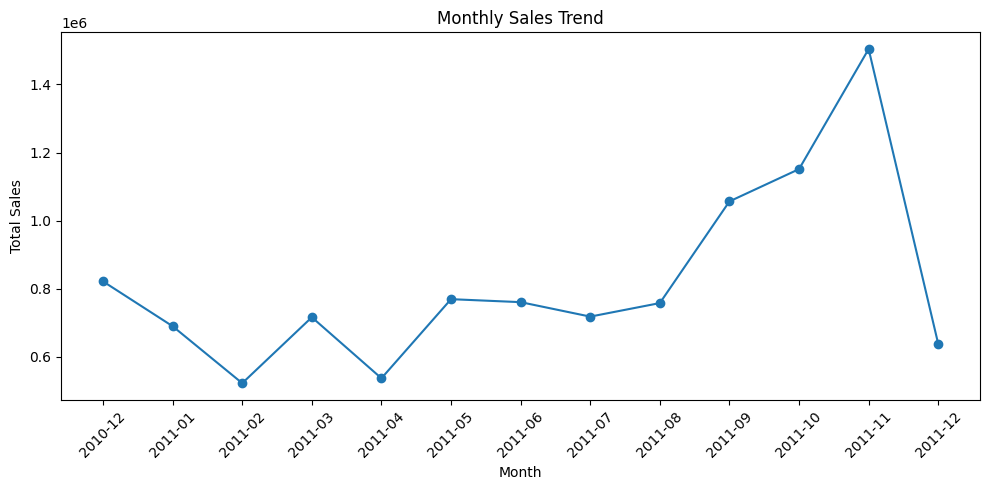

In [ ]:
monthly_sales = clean_df.copy()

monthly_sales["Month"] = monthly_sales["InvoiceDate"].dt.to_period("M")

monthly_sales = monthly_sales.groupby("Month")["TotalSales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

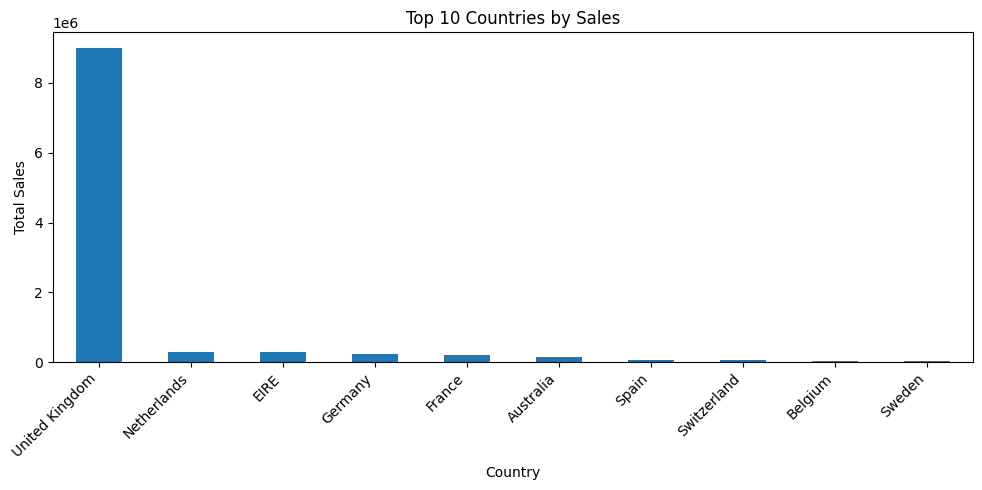

In [ ]:
import matplotlib.pyplot as plt

top_countries = clean_df.groupby("Country")["TotalSales"].sum()
top_countries = top_countries.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_countries.plot(kind="bar")
plt.title("Top 10 Countries by Sales")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print("Total sales:", round(clean_df["TotalSales"].sum(), 2))

print("Average sale:", round(clean_df["TotalSales"].mean(), 2))

print("Median sale:", round(clean_df["TotalSales"].median(), 2))

print("Total quantity sold:", clean_df["Quantity"].sum())

print("Number of countries:", clean_df["Country"].nunique())

display(clean_df["TotalSales"].describe())

Total sales: 10642110.8
Average sale: 20.28
Median sale: 9.92
Total quantity sold: 5572420
Number of countries: 38


,TotalSales
count,524878.000000
mean,20.275399
std,271.693566
min,0.001000
25%,3.900000
50%,9.920000
75%,17.700000
max,168469.600000


In [ ]:
import pandas as pd

df = pd.read_excel("Unit5_Online_Retail.xlsx")

print("Original dataset shape:", df.shape)
display(df.head())

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Data types:")
print(df.dtypes)

clean_df = df.copy()

clean_df = clean_df.drop_duplicates()

clean_df = clean_df.dropna(subset=["Description"])

clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

clean_df["TotalSales"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))

display(clean_df.head())

Original dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate rows: 5268
Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
Original rows: 541909
Cleaned rows: 524878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:
import pandas as pd

df = pd.read_excel("Unit5_Online_Retail.xlsx")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
